In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
plt.style.use("seaborn-v0_8-whitegrid")

# Data Analysis and Parametrisation

We will do some data analysis to find the following model parameters:

+ Arrival rates
  + $\lambda_2$ the rate at which Stage 2 patients arrive
  + $\lambda_3$ the rate at which Stage 3 patients arrive
  + $\lambda_{3-I}$ the rate at which Stage 3-I patients arrive

+ Service rates
  + $\mu_2$ the service rate / exit rate of patients currently at Stage 2
  + $\mu_3$ the service rate / exit rate of patients currently at Stage 3
  + $\mu_{3-I}$ the service rate / exit rate of patients currently at Stage 3-I

+ Deterioration / Improvement rates
  + $r_{2,3}$ the rate Stage 2 patients deteriorate to be Stage 3 patients
  + $r_{3,3-I}$ the rate Stage 3 patients deteriorate to be Stage 3-I patients
  + $r_{3-I,3}$ the rate Stage 3-I patients improve to be Stage 3 patients
  + $r_{3,2}$ the rate Stage 3 patients improve to be Stage 2 patients

+ $\kappa$ the additional additive LoS per bed move


**Summary:** This analysis parameterises an ICU simulation model using two key steps:

 + Bed-Move De-confounding: Disentangles administrative relocation delays from patient illness duration using a Monte Carlo arrival model.
 + Continuous-Time Markov Chain (CTMC): Fits deterioration and improvement rates ($r_{ij}$), and exit rates (effective service rates) ($\mu_i$) across Stage 2, Stage 3, and Stage 3-I. The objective function simultaneously optimizes cumulative time in care levels, holding duration , and in-hospital mortality.   

# Read in data

In [2]:
data = pd.read_csv("../data/icu_data_2025.csv")

# Heuristically assign 'Stage at Admission'

We will also categorise arriving patients as either arriving as Stage 2, Stage 3, or Stage 3-I, according to their "Invasive Ventilation" status:

+ "Invasive Ventilation" = True :: Stage 3-I
+ "Invasive Ventilation" = False :: Stage 3
+ "Invasive Ventilation" = NaN :: Stage 2

Justification: Ventilators generally can be placed in isolation wards, hence categorising these as Stage 3-I. I believe a NaN value is due to the question not being relevant, as the patients enter as step down or transfer patients from elsewhere.

In [3]:
data['Stage at Admission'] = (
    data['Invasive Ventilation']
    .map({False: '3', True: '3-I'})
    .fillna('2')
)

# Where are admissions coming from?

Just a small plot to show some background.

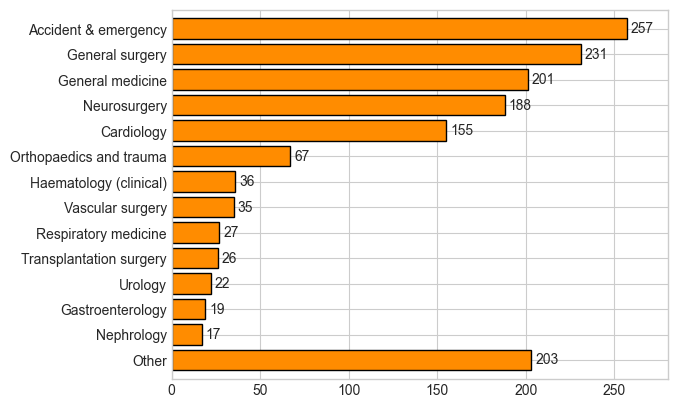

In [4]:
reasons = data['Primary Specialty Treated Prior to Unit Admission'].value_counts()
unknown_count = reasons.get('Unknown Specialty', 0)
reasons_no_unknown = reasons.drop('Unknown Specialty', errors='ignore')
top_n = 13
top_reasons = reasons_no_unknown.iloc[:top_n]
other_reasons = reasons_no_unknown.iloc[top_n:].sum() + unknown_count
squashed_reasons = top_reasons.copy()
squashed_reasons['Other'] = other_reasons

fig, ax = plt.subplots(1)
ax.barh(squashed_reasons.index[::-1], squashed_reasons.values[::-1], color='darkorange', edgecolor='black')
ax.bar_label(plt.gca().containers[0], padding=3)
ax.set_xlim(0, 280)
ax.set_ylim(-0.75, 13.75)
plt.show()

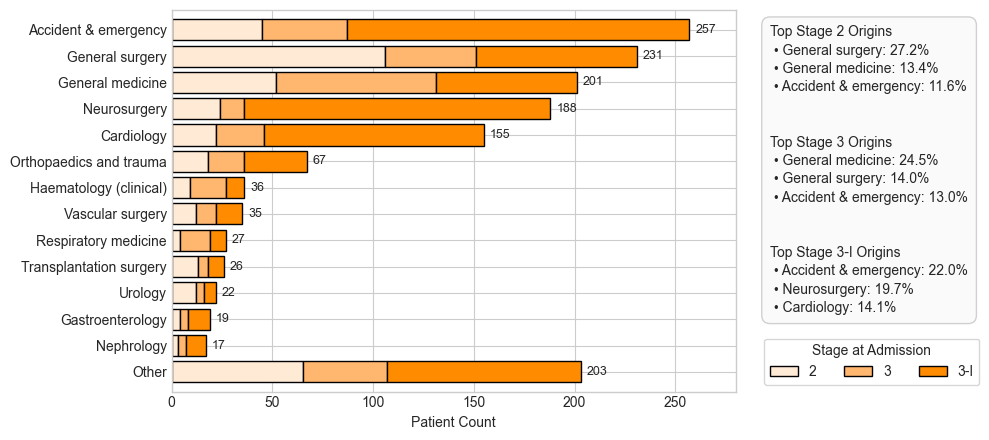

In [5]:
stages = ['2', '3', '3-I']
stage_labels = ['Stage 2', 'Stage 3', 'Stage 3-I']

reasons = data.groupby("Stage at Admission")["Primary Specialty Treated Prior to Unit Admission"].value_counts()
ct = reasons.unstack(level=0, fill_value=0)

# 2. Extract and separate 'Unknown Specialty'
if 'Unknown Specialty' in ct.index:
    unknown_counts = ct.loc['Unknown Specialty']
    ct_no_unknown = ct.drop('Unknown Specialty')
else:
    unknown_counts = 0
    ct_no_unknown = ct

# 3. Identify top 13 specialties by total count across all stages
top_n = 13
totals = ct_no_unknown.sum(axis=1)
top_index = totals.sort_values(ascending=False).head(top_n).index

# 4. Separate top 13 and aggregate remaining rows + unknown into 'Other'
top_reasons = ct_no_unknown.loc[top_index]
other_reasons = ct_no_unknown.drop(top_index).sum(axis=0) + unknown_counts

squashed_reasons = pd.concat([top_reasons, pd.DataFrame([other_reasons], index=['Other'])])

lines = []
for stage_val, label in zip(stages, stage_labels):
    lines.append("")  # Adding a second blank line creates a bigger visual gap
    
    stage_data = data[data['Stage at Admission'] == stage_val]
    total_stage_count = len(stage_data)
    top3 = stage_data['Primary Specialty Treated Prior to Unit Admission'].value_counts().head(3)
    
    lines.append(f"Top {label} Origins")
    for origin, count in top3.items():
        pct = (count / total_stage_count) * 100
        lines.append(f" • {origin}: {pct:.1f}%")
    lines.append("")

summary_text = "\n".join(lines).strip()

fig, (ax_bar, ax_box) = plt.subplots(
    1, 2, 
    figsize=(10, 4.5), 
    gridspec_kw={'width_ratios': [3, 1]}
)

plot_data = squashed_reasons.iloc[::-1]

lefts = np.zeros(len(plot_data))
colors = ['#FFEAD5', '#FFB66F', '#FF8C00']

for i, col in enumerate(plot_data.columns):
    bars = ax_bar.barh(
        plot_data.index, 
        plot_data[col], 
        left=lefts, 
        label=col, 
        color=colors[i], 
        edgecolor='black'
    )
    lefts += plot_data[col].values

totals = plot_data.sum(axis=1).values
for i, total in enumerate(totals):
    ax_bar.text(total + 3, i, str(int(total)), va='center', ha='left', fontsize=9)

handles, labels = ax_bar.get_legend_handles_labels()
ax_bar.set_xlim(0, 280)
ax_bar.set_ylim(-0.75, 13.75)
ax_box.legend(handles=handles, labels=labels, title='Stage at Admission', loc='lower right', bbox_to_anchor=(1.15, 0), frameon=True, ncol=3)
ax_bar.set_xlabel('Patient Count')

ax_box.axis('off')
ax_box.text(
    0.0, 0.96, summary_text,
    transform=ax_box.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.6', facecolor='#FAFAFA', edgecolor='#CCCCCC', alpha=0.9),
    linespacing=1.4
)

plt.tight_layout()
fig.savefig("../plt/admission_stage_by_origin.pdf")

# Investigate $\kappa$

We want to find the extra Length of Stay added to a patient's stay when a bed move occurs. First consider the relationship between the number of bed moves a patient has, and their length of stay. Notice that as the number of bed moves increases, so does LoS (except for n=5 and n=6, but there are so few patients here we cannot draw conclusions). I believe there are two reasons for this:

1) a bed move increases a patient's LoS,
2) the longer a patient's LoS the more likely they are to have a bed move.

Therefore there is a confounding effect akin to inspection bias here. Below we will build a Monte Carlo model to try and disentangle that confounding effect.

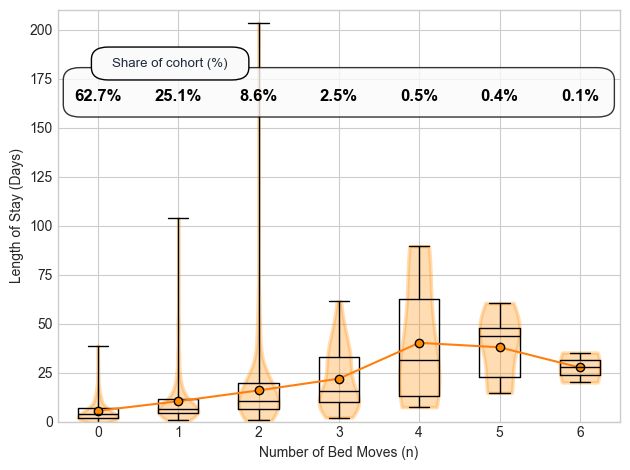

In [6]:
import matplotlib.patches as mpatches
fig, ax = plt.subplots(1)
boxes = ax.boxplot([data[data['Bed movements']==i]['Length of Unit Stay (Days)'] for i in range(7)], positions=range(7), whis=(0, 100), medianprops={'color': 'black'})
viols = ax.violinplot([data[data['Bed movements']==i]['Length of Unit Stay (Days)'] for i in range(7)], positions=range(7), showextrema=False)
ax.plot(range(7), [data[data['Bed movements']==i]['Length of Unit Stay (Days)'].mean() for i in range(7)])
ax.scatter(range(7), [data[data['Bed movements']==i]['Length of Unit Stay (Days)'].mean() for i in range(7)], c='darkorange', edgecolor='black', zorder=2)

emp_means = [data[data['Bed movements'] == i]['Length of Unit Stay (Days)'].mean() for i in range(7)]
emp_pcts = [(data[data['Bed movements'] == i]['Length of Unit Stay (Days)'].count() / len(data)) * 100 for i in range(7)]

for pc in viols['bodies']:
    pc.set_facecolor('darkorange')
    pc.set_edgecolor('darkorange')
    pc.set_linewidth(2.5)

main_box = mpatches.FancyBboxPatch(
    (0.02, 0.75), 0.96, 0.10,
    boxstyle="round,pad=0.01,rounding_size=0.03",
    facecolor="#FAFAFA",
    edgecolor="black",
    linewidth=1,
    transform=ax.transAxes,
    zorder=4,
    clip_on=False,
    alpha=0.8
)
ax.add_patch(main_box)

title_box = mpatches.FancyBboxPatch(
    (0.07, 0.84), 0.26, 0.06,
    boxstyle="round,pad=0.01,rounding_size=0.03",
    facecolor="#FAFAFA",
    edgecolor="black",
    linewidth=1,
    transform=ax.transAxes,
    zorder=6,
    clip_on=False
)
ax.add_patch(title_box)

ax.text(
    0.20, 0.87, "Share of cohort (%)",
    transform=ax.transAxes,
    fontsize=9.5, fontweight='normal', color='#1E293B',
    ha='center', va='center',
    zorder=7
)

for x, y, pct in zip(range(7), emp_means, emp_pcts):
    if not pd.isna(y):
        ax.annotate(f"{pct:.1f}%", (x, 160), textcoords="offset points", 
                    xytext=(0, 5), ha='center', fontsize=12, color="black", zorder=5, fontweight='bold')

ax.set_ylim(0, 210)
ax.set_ylabel("Length of Stay (Days)")
ax.set_xlabel("Number of Bed Moves (n)")
plt.tight_layout()
fig.savefig("../plt/los_by_bedmoves.pdf")

### Monte Carlo model of bed move LoS extensions

In order to disentangle the confounding effect we build a model representing the procress of ranomly choosing patients for a bed move, and then extending their length of stay accordingly. This might then allow further bed moves, and further length of stay extensions.

**Why?**: Raw Length of Stay (LoS) correlates heavily with bed moves, partly due to inspection bias (longer stays naturally accumulate more moves). A naive regression overestimates the disruption penalty. By modeling bed moves as an arrival-driven Poisson process (parameter $\beta$ from the data - justified by bed moves happening on arrivals), we separate intrinsic patient illness duration from administrative delay penalties or condition worsening due to bed moved.

Let:

+ $\widetilde{W}$ be the 'original' or 'adjusted' length of stay _given that no bed moves occurred_ [UNKNOWN];
+ $\kappa$ be the fixed extension to a patient's length of stay for each bed move [UNKNOWN];
+ $W$ be a random variable representing the length of stay _including bed move extention_ [KNOWN];
+ $\mathbb{E}[W(n)]$ be the expected length of stay given that $n$ bed moves occurred [KNOWN];
+ $\beta$ is the rate at which bed moves occur per person, assumed to be Poisson as bed moves can only occur at some subset of patient arrivals [KNOWN].

Then we expect:

$$\mathbb{E}[W(n)] = \mathbb{E}[\widetilde{W} \;| \; n] + n\kappa$$

Note that $\mathbb{E}[W(0)] \neq \mathbb{E}[\widetilde{W}]$, as $W(0)$ contains only the tail of the distribution of $\widetilde{W}$ that was short enough not to have any bed moves occur.

We will build a simulation model of this process, with inputs $\mathbb{E}[\widetilde{W}]$ and $\kappa$, which will measure the distribution of $W$. The parameters will be evaluated against three measures:

+ compare with the known distribution of $\mathbb{E}[W(n)]$;
+ compare with the known distribution of $\mathbb{P}(N = n)$ the probability of the number of bed moves per patient;
+ compare the mean value of $\widetilde{W}$ with $\mathbb{E}[\widetilde{W}]$.

We will perform manual parameter tuning of $\mathbb{E}[\widetilde{W}]$ and $\kappa$ so that the above measures match the empirically observed measures from the data.

In [7]:
def simulate_one_patient(W_original, k, beta):
    """
    A function to simulate one patient's length of stay.
     - First, a 'baseline' LoS is sampled from an Exponential distribution with mean `W_original`.
     - Then the time until the first bed move is sampled, from the parameter `beta`.
     - If that time occurs in the patients current LoS, then extend the LoS by `k`.
     - Sample when the next bed move should occur, and repeat, until the date of the next
       bed move is after the patient has finished their LoS.

    Arguments:
      - `W_original`: the guess at the 'original' or 'adjusted' mean LoS;
      - `k`: the fixed amount of time added to a LoS per bed move;
      - `beta`: the rate at which individuals are subject to a bed move.

    Returns:
      - `W`: the actual LoS;
      - `n`: the number of bed moves that were sampled.
    """
    W = np.random.exponential(W_original)
    n = 0
    next_bed_move = np.random.exponential(1/beta)
    while next_bed_move < W:
        W += k
        n += 1
        next_bed_move += np.random.exponential(1/beta)
    return W, n

After some manual experimentation and calibration, we choose $\mathbb{E}[\widetilde{W}] = 7$ and $\kappa = 2.5$:

In [8]:
k = 1.885
beta = data['Bed movements'].sum() / data['Length of Unit Stay (Days)'].sum()
data['Adjusted LoS'] = (data['Length of Unit Stay (Days)'] - (k * data['Bed movements']))
W_original = data['Adjusted LoS'].mean()

In [9]:
W_original

np.float64(7.346685772083615)

In [10]:
beta

np.float64(0.06526921337318699)

In [11]:
np.random.seed(1)
results = [simulate_one_patient(W_original, k, beta) for _ in range(2500)]

In [12]:
df_sim = pd.DataFrame(results, columns=['value', 'n'])
fit_pcts = (df_sim.groupby('n')['value'].count() / len(df_sim)) * 100
((fit_pcts[1:] / fit_pcts[1:].sum()) * (fit_pcts.index[1:] * k)).sum()

np.float64(3.207203389830509)

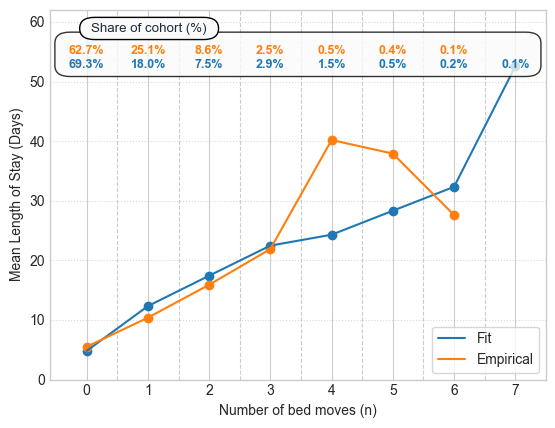

In [13]:
fig, ax = plt.subplots(1)

df_sim = pd.DataFrame(results, columns=['value', 'n'])
fit_means = df_sim.groupby('n')['value'].mean()
fit_pcts = (df_sim.groupby('n')['value'].count() / len(df_sim)) * 100

emp_means = [data[data['Bed movements'] == i]['Length of Unit Stay (Days)'].mean() for i in range(7)]
emp_pcts = [(data[data['Bed movements'] == i]['Length of Unit Stay (Days)'].count() / len(data)) * 100 for i in range(7)]

ax.plot(fit_means.index, fit_means.values, label="Fit")
ax.scatter(fit_means.index, fit_means.values)

ax.plot(range(7), emp_means, label="Empirical")
ax.scatter(range(7), emp_means, color="C1")

main_box = mpatches.FancyBboxPatch(
    (0.02, 0.83), 0.96, 0.10,
    boxstyle="round,pad=0.01,rounding_size=0.03",
    facecolor="#FAFAFA",
    edgecolor="black",
    linewidth=1,
    transform=ax.transAxes,
    zorder=4,
    clip_on=False,
    alpha=0.8
)
ax.add_patch(main_box)

title_box = mpatches.FancyBboxPatch(
    (0.07, 0.93), 0.26, 0.04,
    boxstyle="round,pad=0.01,rounding_size=0.03",
    facecolor="#FAFAFA",
    edgecolor="black",
    linewidth=1,
    transform=ax.transAxes,
    zorder=6,
    clip_on=False
)
ax.add_patch(title_box)

ax.text(
    0.20, 0.95, "Share of cohort (%)",
    transform=ax.transAxes,
    fontsize=9.5, fontweight='normal', color='#1E293B',
    ha='center', va='center',
    zorder=7
)


for x, y, pct in zip(range(7), emp_means, emp_pcts):
    if not pd.isna(y):
        ax.annotate(f"{pct:.1f}%", (x, 53.5), textcoords="offset points", 
                    xytext=(0, 5), ha='center', fontsize=9, color="C1", weight='bold', zorder=5)

for x, y, pct in zip(fit_means.index, fit_means.values, fit_pcts):
    ax.annotate(f"{pct:.1f}%", (x, 53.5), textcoords="offset points", 
                xytext=(0, -5), ha='center', fontsize=9, color="C0", weight='bold', zorder=5)

ax.set_ylim(0, 62)
ax.set_xlim(-0.6,7.5)
ax.legend(frameon=True)
ax.set_xlabel("Number of bed moves (n)")
ax.set_ylabel("Mean Length of Stay (Days)")
ax.set_xticks(np.arange(0, 8, 1), minor=False)
ax.set_xticks(np.arange(0.5, 7.5, 1.0), minor=True)
ax.grid(True, which='minor', axis='x', linestyle='--', color='gray', alpha=0.4)
ax.grid(True, which='major', axis='y', linestyle=':', color='gray', alpha=0.3)
fig.savefig("../plt/monte_carlo_fit.pdf")

Now compare the mean value of $\widetilde{W}$ with $\mathbb{E}[\widetilde{W}]$, and both are equal to 7.

In [14]:
data['Adjusted LoS'] = (data['Length of Unit Stay (Days)'] - (k * data['Bed movements']))

In [15]:
average_LoS_increase = ((fit_pcts[1:] / fit_pcts[1:].sum()) * (fit_pcts.index[1:] * k)).sum()
average_LoS_increase

np.float64(3.207203389830509)

In [16]:
k, W_original

(1.885, np.float64(7.346685772083615))

The mean adjusted LoS is equal to the modelled expected original LoS, this confirms that the model is internally consistant.

Now the adjusted distribution does have some negative values, but there is only 3\% and clustered around 0 as shown below, which would be expected as in reality the increment $\kappa$ would be a random variable, but it is only deterministic in this model.

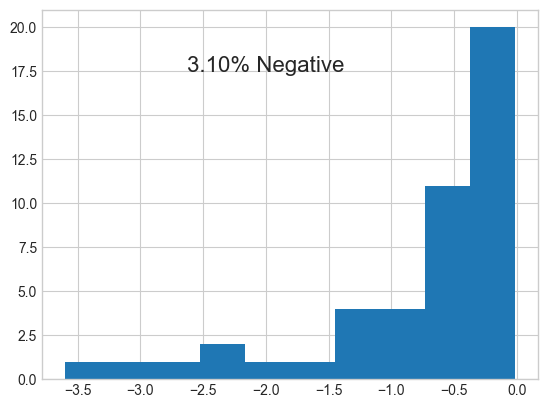

In [17]:
data[data['Adjusted LoS'] < 0]['Adjusted LoS'].hist()
pct = (data['Adjusted LoS'] < 0).mean() * 100
plt.annotate(f"{pct:.2f}% Negative", (-2, 17.5), ha='center', fontsize=16)
plt.show()

Therefore we can lock in the parameter:

$$\kappa = 1.885$$

# Deterioration and Improvement Rates

Here we will look at deterioration and improvement rates. From the heuristic labelling above we used "Invasive Ventilation" to categorise patients into arriving stages 2, 3, and 3-I.

During their stay we know the total number of days spent in care levels 0, 1, 2, and 3. Assume that:

+ Care levels 0, 1, and 2 correspond to being in Stage 2;
+ Care level 3 corresponds to being in either Stage 3 or Stage 3-I.

First we consider the LoS and days in each care level by arriving stage:

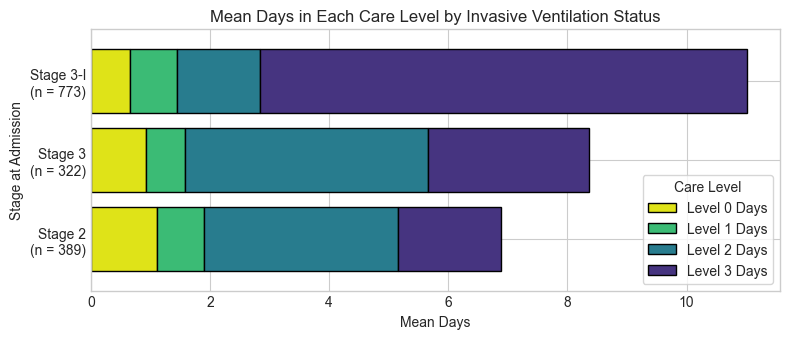

In [18]:
grouped_df = data.groupby('Stage at Admission', dropna=False)[['Level ' + str(i) + ' Days' for i in range(4)]].mean()

custom_colors = [plt.colormaps['viridis_r'](i) for i in np.linspace(0.05, 0.85, 4)]
fig, ax = plt.subplots(1, figsize=(8, 3.5))
grouped_df.plot.barh(stacked=True, color=custom_colors, ax=ax, edgecolor='black', width=0.8)
ax.set_ylabel('Stage at Admission')
ax.set_xlabel('Mean Days')
ax.set_title('Mean Days in Each Care Level by Invasive Ventilation Status')
plt.xticks(rotation=0)
ax.legend(title='Care Level', frameon=True)
ax.set_yticklabels(
    [f"Stage {i}\n(n = {data['Stage at Admission'].value_counts()[i]})" for i in ['2', '3', '3-I']]
)
plt.tight_layout()
plt.show()

The above plot included all LoS extensions due to bed moves. If we look at the adjusted LoS assuming no bed moves occured (that is minus $n \kappa$ from each Length of Stay, and proportionally remove that amount from each Care Level; ignoring the 5% of negative):

In [19]:
data_adjusted = data[data['Adjusted LoS'] > 0].copy()
data_adjusted['multiplier'] = data['Adjusted LoS'] / data['Length of Unit Stay (Days)']

In [20]:
data_adjusted['Level 3 Days Adjusted'] = data_adjusted['Level 3 Days'] * data_adjusted['multiplier']
data_adjusted['Level 2 Days Adjusted'] = data_adjusted['Level 2 Days'] * data_adjusted['multiplier']
data_adjusted['Level 1 Days Adjusted'] = data_adjusted['Level 1 Days'] * data_adjusted['multiplier']
data_adjusted['Level 0 Days Adjusted'] = data_adjusted['Level 0 Days'] * data_adjusted['multiplier']

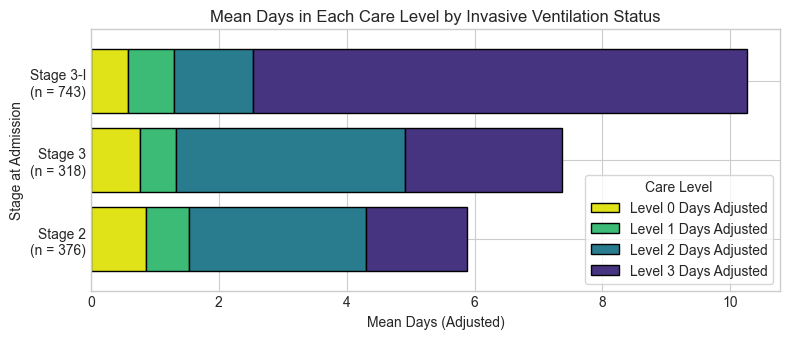

In [21]:
grouped_df = data_adjusted.groupby('Stage at Admission', dropna=False)[['Level ' + str(i) + ' Days Adjusted' for i in range(4)]].mean()

# grouped_df = pd.DataFrame({'Stage 2 Care Days': grouped_df[['Level 0 Days Adjusted', 'Level 1 Days Adjusted', 'Level 2 Days Adjusted']].sum(axis=1), 'Stage 3 / 3-I Care Days': grouped_df['Level 3 Days Adjusted']})

custom_colors = [plt.colormaps['viridis_r'](i) for i in np.linspace(0.05, 0.85, 4)]
fig, ax = plt.subplots(1, figsize=(8, 3.5))
grouped_df.plot.barh(stacked=True, color=custom_colors, ax=ax, edgecolor='black', width=0.8)
ax.set_ylabel('Stage at Admission')
ax.set_xlabel('Mean Days (Adjusted)')
ax.set_title('Mean Days in Each Care Level by Invasive Ventilation Status')
plt.xticks(rotation=0)
ax.legend(title='Care Level', frameon=True)
ax.set_yticklabels(
    [f"Stage {i}\n(n = {data_adjusted['Stage at Admission'].value_counts()[i]})" for i in ['2', '3', '3-I']]
)
plt.tight_layout()
plt.show()

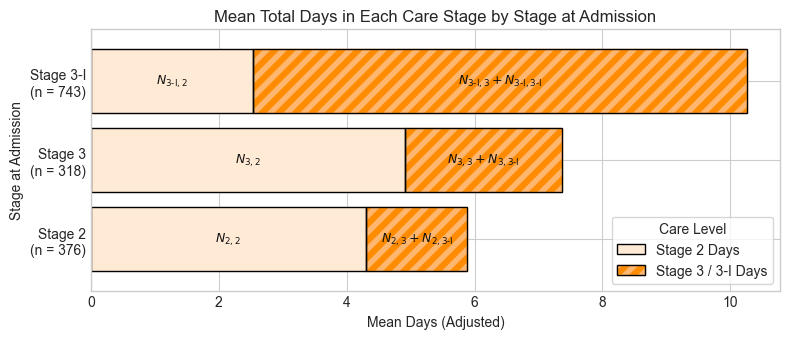

In [22]:
from matplotlib.legend_handler import HandlerPatch

grouped_df = data_adjusted.groupby('Stage at Admission', dropna=False)[['Level ' + str(i) + ' Days Adjusted' for i in range(4)]].mean()

grouped_df = pd.DataFrame({'Stage 2 Care Days': grouped_df[['Level 0 Days Adjusted', 'Level 1 Days Adjusted', 'Level 2 Days Adjusted']].sum(axis=1), 'Stage 3 / 3-I Care Days': grouped_df['Level 3 Days Adjusted']})

custom_colors = colors = ['#FFEAD5', '#FFB66F', '#FF8C00']
plt.rcParams['hatch.color'] = custom_colors[1]
plt.rcParams['hatch.linewidth'] = 4

fig, ax = plt.subplots(1, figsize=(8, 3.5))
grouped_df.plot.barh(stacked=True, ax=ax, edgecolor=None, width=0.8, legend=False)

for patch in ax.containers[0]:
    patch.set_facecolor(custom_colors[0])
    patch.set_edgecolor(custom_colors[0])

for patch in ax.containers[1]:
    patch.set_facecolor(custom_colors[2])
    patch.set_hatch('//')
    patch.set_edgecolor(custom_colors[1])  # Sets the hatch stripe color

grouped_df.plot.barh(stacked=True, ax=ax, edgecolor='black', width=0.8, facecolor='None', legend=False)

ax.set_ylabel('Stage at Admission')
ax.set_xlabel('Mean Days (Adjusted)')
ax.set_title('Mean Total Days in Each Care Stage by Stage at Admission')
plt.xticks(rotation=0)

# 4. Custom Legend Handler to overlay black border over the hatched swatch
class HatchedHandler(HandlerPatch):
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        # Base hatched patch
        p1 = super().create_artists(legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans)[0]
        # Black outer border patch
        p2 = mpatches.Rectangle(
            (xdescent, ydescent), width, height,
            facecolor='none', edgecolor='black', linewidth=1.0, transform=trans
        )
        return [p1, p2]

# Build Legend Handles
legend_handles = [
    mpatches.Patch(
        facecolor=custom_colors[0], 
        edgecolor='black', 
        linewidth=1.0,
        label='Stage 2 Days'
    ),
    mpatches.Patch(
        facecolor=custom_colors[2], 
        hatch='//', 
        edgecolor=custom_colors[1], 
        linewidth=1.0,
        label='Stage 3 / 3-I Days'
    )
]

ax.legend(
    handles=legend_handles, 
    handler_map={legend_handles[1]: HatchedHandler()}, 
    title='Care Level', 
    frameon=True
)

ax.set_yticklabels(
    [f"Stage {i}\n(n = {data_adjusted['Stage at Admission'].value_counts()[i]})" for i in ['2', '3', '3-I']]
)

## Annotate
MC_labels = [[r"$N_{2, 2}$", r"$N_{2, 3} + N_{2, 3\text{-I}}$"], [r"$N_{3, 2}$", r"$N_{3, 3} + N_{3, 3\text{-I}}$"], [r"$N_{3\text{-I}, 2}$", r"$N_{3\text{-I}, 3} + N_{3\text{-I}, 3\text{-I}}$"]]
for i, container in enumerate(ax.containers[:2]):
    for j, patch in enumerate(container):
        bbox = patch.get_bbox()
        val = bbox.width
        
        x_center = bbox.x0 + bbox.width / 2.0
        y_center = bbox.y0 + bbox.height / 2.0
        ax.text(
            x_center, y_center, MC_labels[j][i],
            ha='center', va='center',
            fontsize=9, fontweight='bold',
            color='#111111',
        )

plt.tight_layout()
fig.savefig("../plt/overall_care_days_by_admission_stage.pdf")

In [23]:
import os
print(os.path.exists("../images/CTMC.png"))  # Returns True

True


### CTMC model of deterioration and improvement

We want to extract deterioration, improvement, and exit rates, given the aggregated empirical data above.

First build the following Makov chain, showing the deterioration and improvement of patients throughout their stay at the ICU.

**Why?**: Empirical data only shows a 'shadow' of the hypothesised deterioration and improvement dynamic, e.g. overall proportion of stay in each care category. Markov chain theory allows us to measure these 'shadows', while parameterising deterioration and improvement rates explicitly.


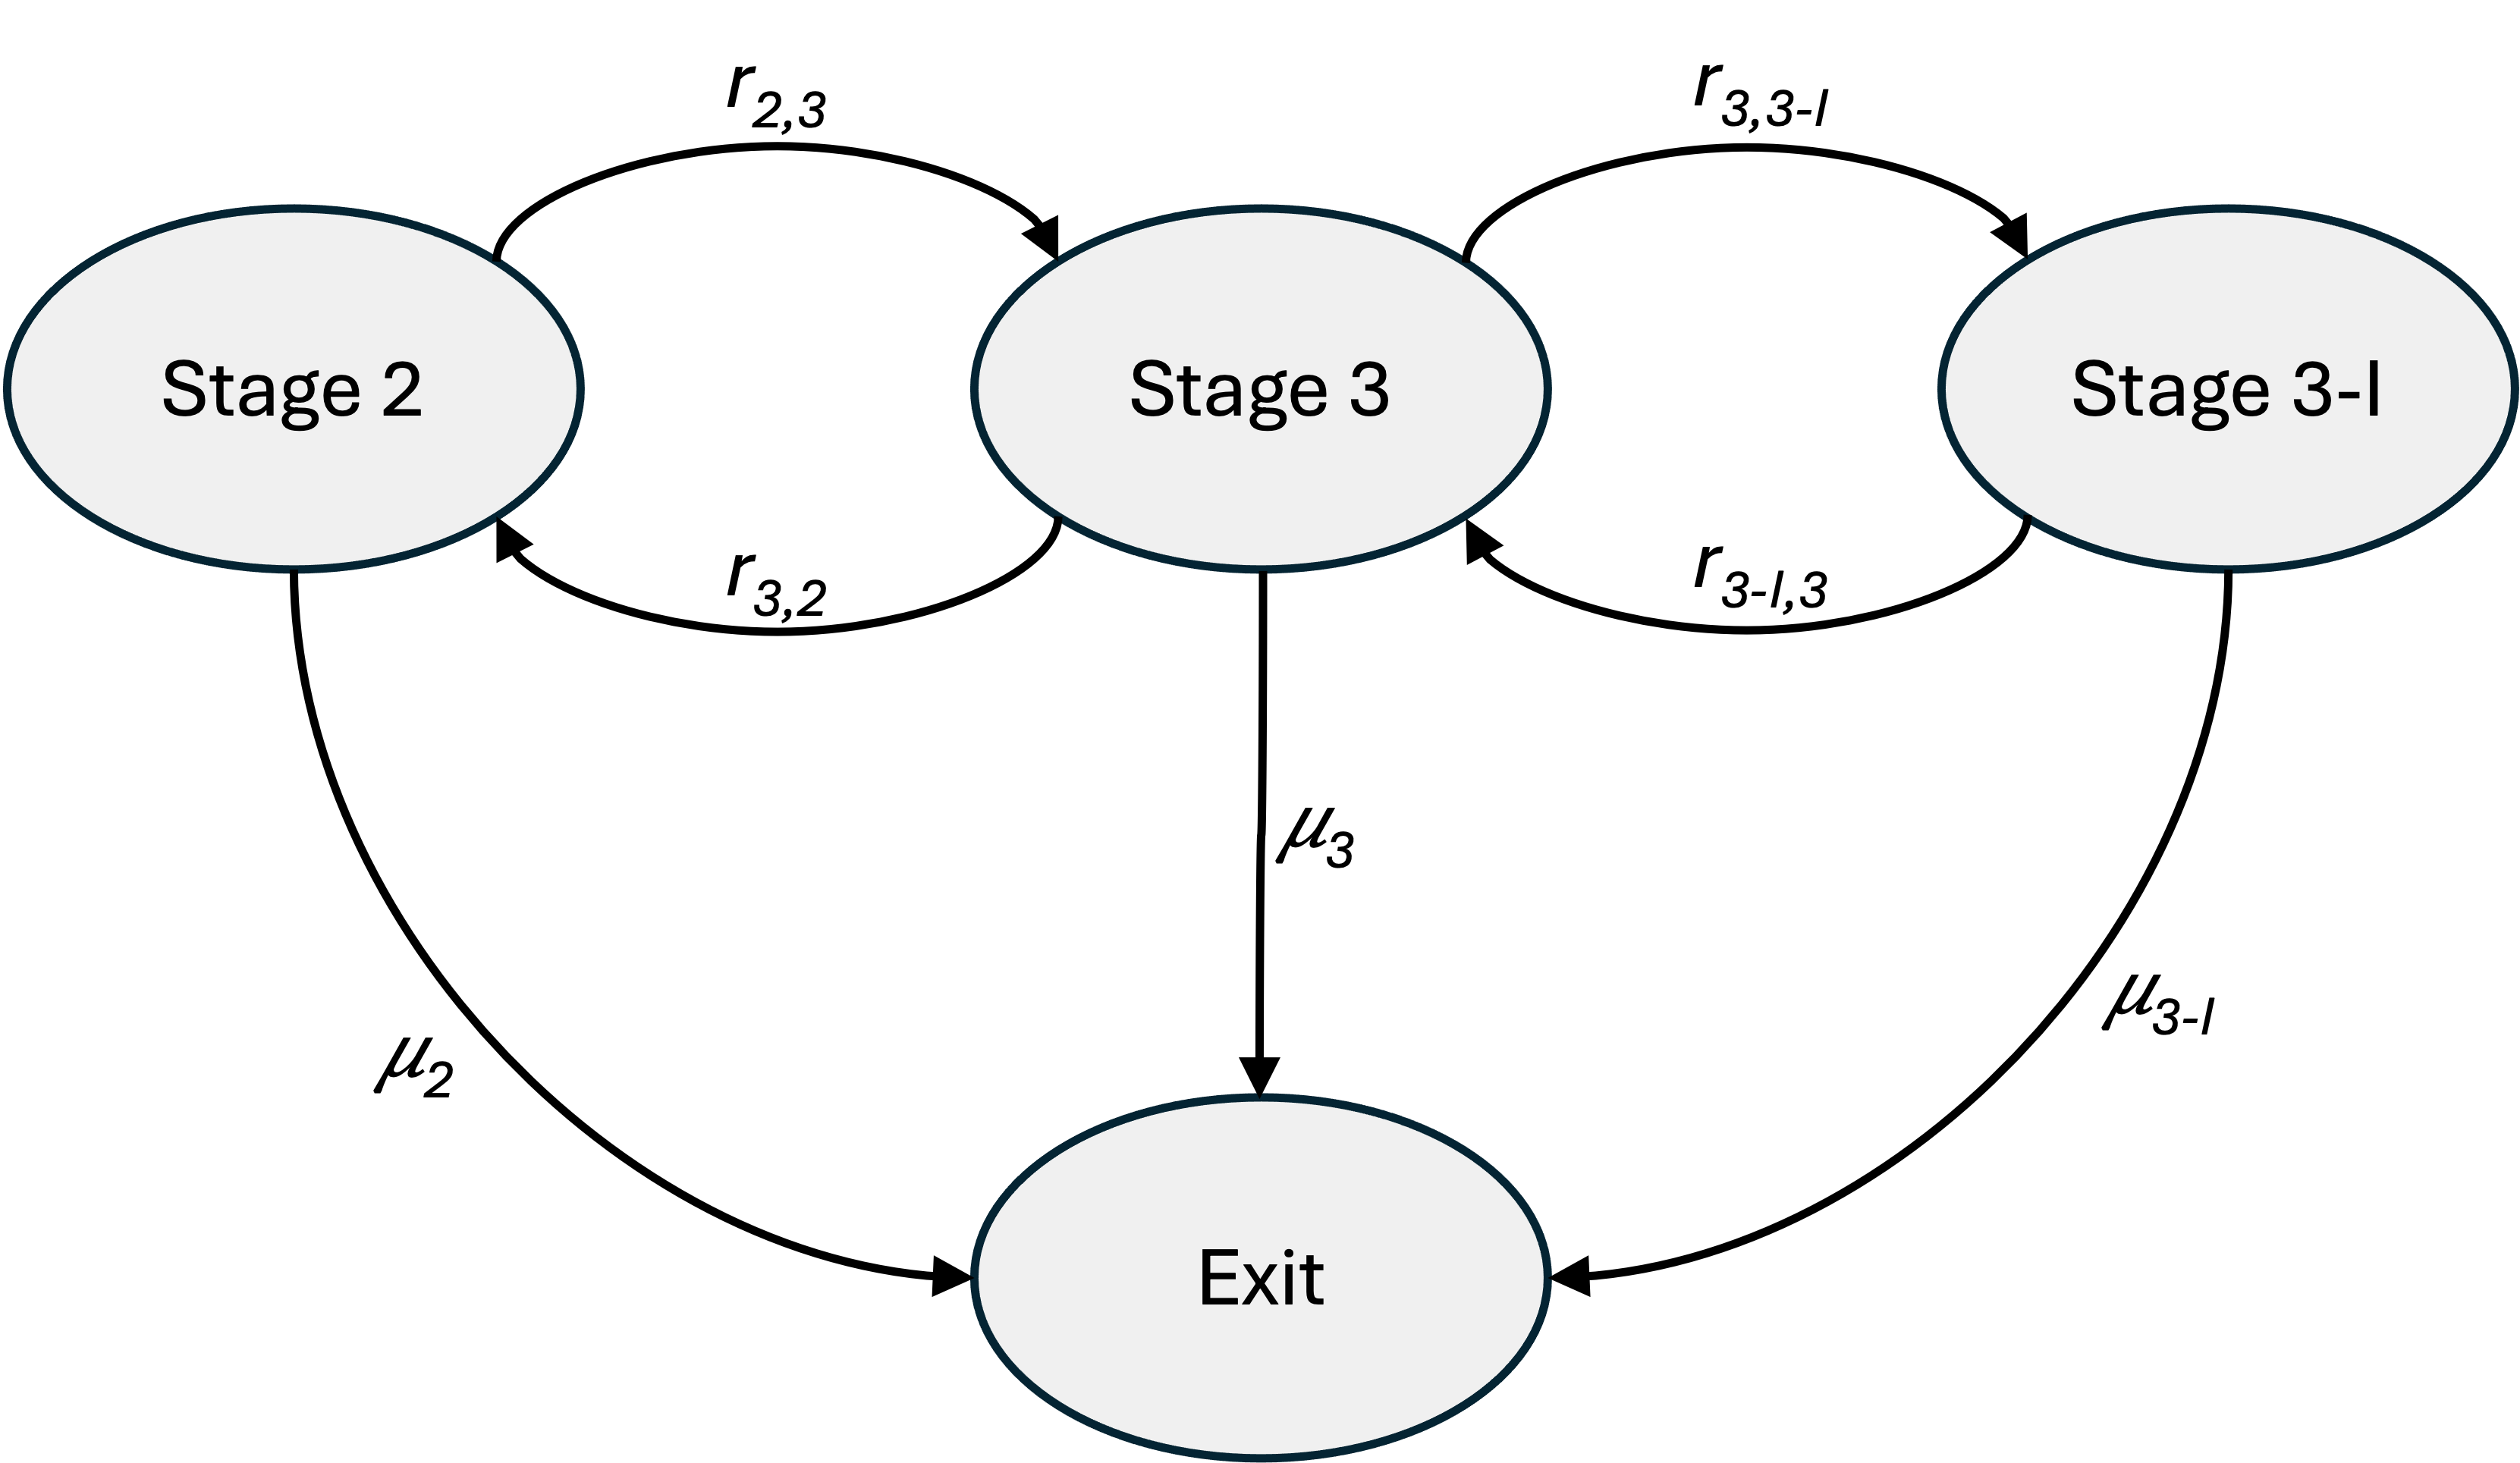

In [24]:
from IPython.display import Image, display
display(Image(filename="../images/CTMC.png", width=750))

This is an absorbing Markov chain with transition rate matrix:

$$
Q = \begin{pmatrix}
-(r_{23} + \mu_2) & r_{23} & 0 & \mu_2 \\
r_{32} & -(r_{32} + r_{33I} + \mu_3) & r_{33I} & \mu_{3} \\
0 & r_{3I3} & -(r_{3I3} + \mu_{3I}) & \mu_{3I} \\
0 & 0 & 0 & 0 \\
\end{pmatrix}
$$

This has the following block structure:

$$
Q = \begin{bmatrix} R & T \\ 0 & 0 \end{bmatrix}
$$

Then the fundemental matrix is $N = -R^{-1}$, where the entries $N_{ij}$ are the expected time spent in state $j$ given a starting state $i$.

In [25]:
import sympy as sym

r23 = sym.Symbol("r_{23}")
r33I = sym.Symbol("r_{33I}")
r3I3 = sym.Symbol("r_{3I3}")
r32 = sym.Symbol("r_{32}")
mu2 = sym.Symbol(r"\mu_{2}")
mu3 = sym.Symbol(r"\mu_{3}")
mu3I = sym.Symbol(r"\mu_{3I}")

In [26]:
R = sym.Matrix([[-(r23 + mu2), r23, 0], [r32, -(r32 + r33I + mu3), r33I], [0, r3I3, -(r3I3 + mu3I)]])

In [27]:
N = (-R).inv()
N

Matrix([
[(\mu_{3I}*\mu_{3} + \mu_{3I}*r_{32} + \mu_{3I}*r_{33I} + \mu_{3}*r_{3I3} + r_{32}*r_{3I3})/(\mu_{2}*\mu_{3I}*\mu_{3} + \mu_{2}*\mu_{3I}*r_{32} + \mu_{2}*\mu_{3I}*r_{33I} + \mu_{2}*\mu_{3}*r_{3I3} + \mu_{2}*r_{32}*r_{3I3} + \mu_{3I}*\mu_{3}*r_{23} + \mu_{3I}*r_{23}*r_{33I} + \mu_{3}*r_{23}*r_{3I3}),                                      (\mu_{3I}*r_{23} + r_{23}*r_{3I3})/(\mu_{2}*\mu_{3I}*\mu_{3} + \mu_{2}*\mu_{3I}*r_{32} + \mu_{2}*\mu_{3I}*r_{33I} + \mu_{2}*\mu_{3}*r_{3I3} + \mu_{2}*r_{32}*r_{3I3} + \mu_{3I}*\mu_{3}*r_{23} + \mu_{3I}*r_{23}*r_{33I} + \mu_{3}*r_{23}*r_{3I3}),                                                                         r_{23}*r_{33I}/(\mu_{2}*\mu_{3I}*\mu_{3} + \mu_{2}*\mu_{3I}*r_{32} + \mu_{2}*\mu_{3I}*r_{33I} + \mu_{2}*\mu_{3}*r_{3I3} + \mu_{2}*r_{32}*r_{3I3} + \mu_{3I}*\mu_{3}*r_{23} + \mu_{3I}*r_{23}*r_{33I} + \mu_{3}*r_{23}*r_{3I3})],
[                                                        (\mu_{3I}*r_{32} + r_{32}*r_{3I3})/(\mu_{2}*\mu_{3I}*\m

I then have the following known values from the plot above:

+ $N_{2, 2}$: the days spent in Care level 0, 1, or 2, given they started at Stage 2
+ $N_{2, 3} + N_{2, 3I}$: the days spent in Care level 3, given they started at Stage 2
+ $N_{3, 2}$: the days spent in Care level 0, 1, or 2, given they started at Stage 3
+ $N_{3, 3} + N_{3, 3I}$: the days spent in Care level 3, given they started at Stage 3
+ $N_{3I, 2}$: the days spent in Care level 0, 1, or 2, given they started at Stage 3-I
+ $N_{3I, 3} + N_{3I, 3I}$: the days spent in Care level 3, given they started at Stage 3-I

This is still indiscriminate - we may know the overall time spent in each state before exit, but not how many jumps between those states. In order to enforce a discriminate solution, we can make an assumtion about one state's holding time, that is the expected amount of time spent in a state before deteriorating or improving. We only need to make an assumption about of the states, so choose $H_{3I} = 3.0$. (The exact value here is not too important, it is only imporant that the scale is realistic, i.e. in days, rather than years of seconds).

Holding times are given by the negative inverse diagonals of $R$, hence:

$$H_{3I} = (r_{3I3} + \mu_{3I})^{-1} = 3.0$$

We can also fit the absoption proportions, that is the proporiton of patients exiting directly from particular stage. From the data we can find the `Unit Discharge Status`, indicating if the patients left dead or alive. We can assume that those patients who died exited while in Stage 3-I, and those patients who exited alive exited from stages 2 and 3. Therefore we can also fit:

$$A_{3I} = \mu_{3I} \sum_{i \in (2, 3, 3I)} p_i N_{i, 3I} = \text{Proportion exiting due to death}$$

In [28]:
T = sym.Matrix([[1, 0], [0, 1], [0, 1]])
N @ T

Matrix([
[(\mu_{3I}*\mu_{3} + \mu_{3I}*r_{32} + \mu_{3I}*r_{33I} + \mu_{3}*r_{3I3} + r_{32}*r_{3I3})/(\mu_{2}*\mu_{3I}*\mu_{3} + \mu_{2}*\mu_{3I}*r_{32} + \mu_{2}*\mu_{3I}*r_{33I} + \mu_{2}*\mu_{3}*r_{3I3} + \mu_{2}*r_{32}*r_{3I3} + \mu_{3I}*\mu_{3}*r_{23} + \mu_{3I}*r_{23}*r_{33I} + \mu_{3}*r_{23}*r_{3I3}),                                                                         r_{23}*r_{33I}/(\mu_{2}*\mu_{3I}*\mu_{3} + \mu_{2}*\mu_{3I}*r_{32} + \mu_{2}*\mu_{3I}*r_{33I} + \mu_{2}*\mu_{3}*r_{3I3} + \mu_{2}*r_{32}*r_{3I3} + \mu_{3I}*\mu_{3}*r_{23} + \mu_{3I}*r_{23}*r_{33I} + \mu_{3}*r_{23}*r_{3I3}) + (\mu_{3I}*r_{23} + r_{23}*r_{3I3})/(\mu_{2}*\mu_{3I}*\mu_{3} + \mu_{2}*\mu_{3I}*r_{32} + \mu_{2}*\mu_{3I}*r_{33I} + \mu_{2}*\mu_{3}*r_{3I3} + \mu_{2}*r_{32}*r_{3I3} + \mu_{3I}*\mu_{3}*r_{23} + \mu_{3I}*r_{23}*r_{33I} + \mu_{3}*r_{23}*r_{3I3})],
[                                                        (\mu_{3I}*r_{32} + r_{32}*r_{3I3})/(\mu_{2}*\mu_{3I}*\mu_{3} + \mu_{2}*\mu_{3I}*r_{32} + \m

In [29]:
rhs = data_adjusted.groupby('Stage at Admission')[['Level 0 Days Adjusted', 'Level 1 Days Adjusted', 'Level 2 Days Adjusted', 'Level 3 Days Adjusted']].mean()
rhs['Days as Stage 2'] = rhs['Level 0 Days Adjusted'] + rhs['Level 1 Days Adjusted'] + rhs['Level 2 Days Adjusted']
rhs['Days as Stage 3 or 3-I'] = rhs['Level 3 Days Adjusted']
rhs = rhs[['Days as Stage 2', 'Days as Stage 3 or 3-I']]

In [30]:
rhs

,Days as Stage 2,Days as Stage 3 or 3-I
Stage at Admission,,
2,4.306320,1.581606
3,4.908388,2.455036
3-I,2.543812,7.719336


In [31]:
initial_p = np.array([data_adjusted['Stage at Admission'].value_counts()[i] / data_adjusted['Stage at Admission'].value_counts().sum() for i in ['2', '3', '3-I']])
initial_p

array([0.26165623, 0.22129436, 0.51704941])

In [32]:
target_H3I = 3.0
target_A3I = data_adjusted['Unit Discharge Status'].value_counts()['Dead'] / len(data_adjusted)

In [33]:
rhs = rhs.to_numpy()
f = sym.lambdify([r23, r33I, r3I3, r32, mu2, mu3, mu3I], N @ T, 'numpy')

In [34]:
H3I = sym.lambdify([r23, r33I, r3I3, r32, mu2, mu3, mu3I], 1 / (-R[2, 2]), 'numpy')

In [35]:
A3I = sym.lambdify([r23, r33I, r3I3, r32, mu2, mu3, mu3I], N[:,2].dot(initial_p) * mu3I, 'numpy')

In [36]:
def loss_function(x):
    """
    A loss function used to evaluate our guesses at values of r23, r33I, r3I3, r32, mu2, mu3, and mu3I.

    It consists of 3 parts:
     - `proportions_loss`: this compares the model's predicted overall proportion of time spent in each state,
          given a particular starting state; and compares it to the observed values in `rhs`.
     - `holding_loss`: this compares the model's predicted expected holding time in Stage 3-I, and compares it
          to the "reasonable guess" of 3.0 days.
     - `absorption_loss`: this compares the model's predicted proportion of exits via stage 3-I (assumed due to
          death), against the proportion of patients with "death" as a discharge status in the data.

    All losses are calculated as the Mean Percentage Squared Error (MPSE).

    Arguments:
      - x: a guess at the vector (r23, r33I, r3I3, r32, mu2, mu3, mu3I)

    Returns: the sum of the MPSE of each of the three parts above.
    """
    r23, r33I, r3I3, r32, mu2, mu3, mu3I = x

    predicted_proportions = f(r23, r33I, r3I3, r32, mu2, mu3, mu3I)
    proportions_loss = (((predicted_proportions - rhs) / rhs) ** 2).sum()  # Fit Ns: proportions of time spent in each stage overall
    
    predicted_holdingtime = H3I(r23, r33I, r3I3, r32, mu2, mu3, mu3I)
    holding_loss = ((predicted_holdingtime - target_H3I) / target_H3I) ** 2  # Fit H3I: the holding time in Stage 3-I

    predicted_absorptionprop = A3I(r23, r33I, r3I3, r32, mu2, mu3, mu3I)
    absorption_loss = ((predicted_absorptionprop - target_A3I) / target_A3I) ** 2  # Fit A2: the proportion of exits from Stage 2
    
    return proportions_loss + absorption_loss + holding_loss

In [37]:
import scipy.optimize

In [38]:
bounds = [(1e-2, None) for _ in range(7)]
initial_guess = [5, 5, 5, 5, 5, 5, 5]
sol = scipy.optimize.minimize(loss_function, x0=initial_guess, bounds=bounds)

In [39]:
sol

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.16220294322566914
        x: [ 3.410e-01  1.000e-02  1.901e-01  9.572e-01  2.249e-01
             1.000e-02  1.043e-01]
      nit: 81
      jac: [ 3.231e-06  9.190e-02 -1.965e-06 -6.606e-07 -1.901e-05
             2.426e-02 -1.598e-05]
     nfev: 1064
     njev: 133
 hess_inv: <7x7 LbfgsInvHessProduct with dtype=float64>

In [40]:
(sol.fun / 8) * 100

np.float64(2.0275367903208643)

In [41]:
sol.x

array([0.3410191 , 0.01      , 0.19009786, 0.95716634, 0.22487619,
       0.01      , 0.10428896])

In [42]:
f(*sol.x), rhs

(array([[4.35475915, 1.58183543],
        [4.29400491, 2.62493573],
        [2.7728182 , 5.0919218 ]]),
 array([[4.30632035, 1.58160614],
        [4.90838844, 2.45503649],
        [2.54381171, 7.71933627]]))

In [43]:
A3I(*sol.x), target_A3I

(np.float64(0.18958011010101497), np.float64(0.1871955462769659))

In [44]:
H3I(*sol.x), target_H3I

(np.float64(3.396891235280842), 3.0)

Therefore we can conlcude:

+ $r_{23} = 0.341$
+ $r_{33I} = 0.01$
+ $r_{3I3} = 0.190$
+ $r_{32} = 0.957$
+ $\mu_2 = 0.225$
+ $\mu_3 = 0.01$
+ $\mu_{3I} = 0.104$

It'll also be useful to have the general expected length of stay for patients arriving in each Stage, $s_2$, $s_3$, and $s_{3-I}$. This is obtained by summing the rows of the fundemental matrix $N$, that is:

$$
\begin{pmatrix}
s_2 \\
s_3 \\
s_{3-I}
\end{pmatrix} = N \begin{pmatrix}
1 \\
1 \\
1
\end{pmatrix}
$$

In [45]:
mean_time_to_absorption = N.subs(
    {
        r23: sol.x[0],
        r33I: sol.x[1],
        r3I3: sol.x[2],
        r32: sol.x[3],
        mu2: sol.x[4],
        mu3: sol.x[5],
        mu3I: sol.x[6],
    }
) @ sym.Matrix([[1], [1], [1]])
mean_time_to_absorption

Matrix([
[   5.93659458278],
[6.91894064394252],
[ 7.8647399974503]])

# Arrival Rates

Arrival rates for patients beginning in each stage are easily found:

In [46]:
data['Stage at Admission'].value_counts() / 365

Stage at Admission
3-I    2.117808
2      1.065753
3      0.882192
Name: count, dtype: float64

Hence:

+ $\lambda_2 = 1.0658$
+ $\lambda_3 = 0.8822$
+ $\lambda_{3-I} = 2.1178$

In [47]:
number_of_beds = 34
traffic_intensity = (len(data) / 365) / ((1 / data['Length of Unit Stay (Days)'].mean()) * number_of_beds)
traffic_intensity

np.float64(1.0012457695406929)

The observed traffic intensity is greater than 1, implying that the queue to the ICU grows indefinitely. This cannot be true. Some reaons include: not all beddays take place in the ICU (some patients are sent to surge); additional beds can be aquisitioned to deal with heavy traffic, etc. So say a reasonable traffic intensity is around $\rho = 0.75$, we can scale down the arrivals to reflect this by a factor of $\eta$.

$$
0.75 = \eta 1.0012
$$

Hence $\eta = 0.75 / 1.0012$

In [48]:
eta = 0.75 / traffic_intensity
eta

np.float64(0.7490668353525746)

In [49]:
(data['Stage at Admission'].value_counts() / 365) * eta

Stage at Admission
3-I    1.586380
2      0.798321
3      0.660821
Name: count, dtype: float64

# Summary Table



| Parameter       | Value  | Units        | How                              |
| --------------- | ------ | -------------| -------------------------------- |
| $\lambda_2$     | 0.7983 | people / day | Directly from data & Scaled down |
| $\lambda_3$     | 0.6608 | people / day | Directly from data & Scaled down |
| $\lambda_{3-I}$ | 1.5864 | people / day | Directly from data & Scaled down |
| $\mu_2$         | 0.225  | people / day | Fitted (CTMC model)              |
| $\mu_3$         | 0.01   | people / day | Fitted (CTMC model)              |
| $\mu_{3-I}$     | 0.104  | people / day | Fitted (CTMC model)              |
| $r_{2,3}$       | 0.341  | people / day | Fitted (CTMC model)              |
| $r_{3,3-I}$     | 0.01   | people / day | Fitted (CTMC model)              |
| $r_{3-I,3}$     | 0.190  | people / day | Fitted (CTMC model)              |
| $r_{3,2}$       | 0.957  | people / day | Fitted (CTMC model)              |
| $s_2$           | 5.937  | days         | Fitted (CTMC model)              |
| $s_3$           | 6.919  | days         | Fitted (CTMC model)              |
| $s_{3-I}$       | 7.865  | days         | Fitted (CTMC model)              |
| $\kappa$        | 1.885  | days         | Fitted (Monte Carlo model)       |
